# GTW-Tree — kết quả chi tiết (Li, Wang & Wu 2024)

`run_gtw.py`: mỗi điểm đích (ô, ngày) dựng một mô hình cây (RF / XGBoost / LightGBM, tham số mặc định) từ mẫu train trong 30 ngày trước, trọng số Gaussian w = exp(−(ds² + λ·dt²) / h²) với h = khoảng cách tới mẫu gần thứ N0, cộng 3 mẫu non-local. λ và N0 chọn bằng vòng lặp lồng trên ô validation của vòng trong. So sánh với các mô hình khác: `../../compare_models.ipynb`.

## 0. Thiết lập

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 110
MODEL_DIR = Path.cwd().parents[1]                        # pm25_map/model
sys.path.insert(0, str(MODEL_DIR))
import _data as D, _results as R
frame = D.build_frame(); cells = R.cell_table(frame)
OUT = MODEL_DIR / 'local_model' / 'gtw_tree' / 'output'
grids = {a: pd.read_csv(OUT / a / 'inner_grid.csv') for a in R.ALGO if (OUT / a / 'inner_grid.csv').exists()}
preds = R.load_gtw()
print('lưới đã có:', {a: f'{g.fold.nunique()} fold, {len(g)} tổ hợp' for a, g in grids.items()})
print('dự đoán test:', {k: sorted(v.outer_fold.unique().tolist()) for k, v in preds.items()})

lưới đã có: {'rf': '5 fold, 100 tổ hợp', 'xgb': '5 fold, 100 tổ hợp', 'lgbm': '5 fold, 100 tổ hợp'}
dự đoán test: {'GTW-RF': [0, 1, 2, 3, 4], 'GTW-XGBoost': [0, 1, 2, 3, 4], 'GTW-LightGBM': [0, 1, 2, 3, 4]}


## 1. Vòng lặp lồng λ × N0
R² validation TB qua các fold. λ có đơn vị km²/ngày², nên 1 ngày tương đương √λ km. N0 càng lớn thì kernel càng rộng; N0 = 2048 gần như lấy mọi mẫu trong 30 ngày.

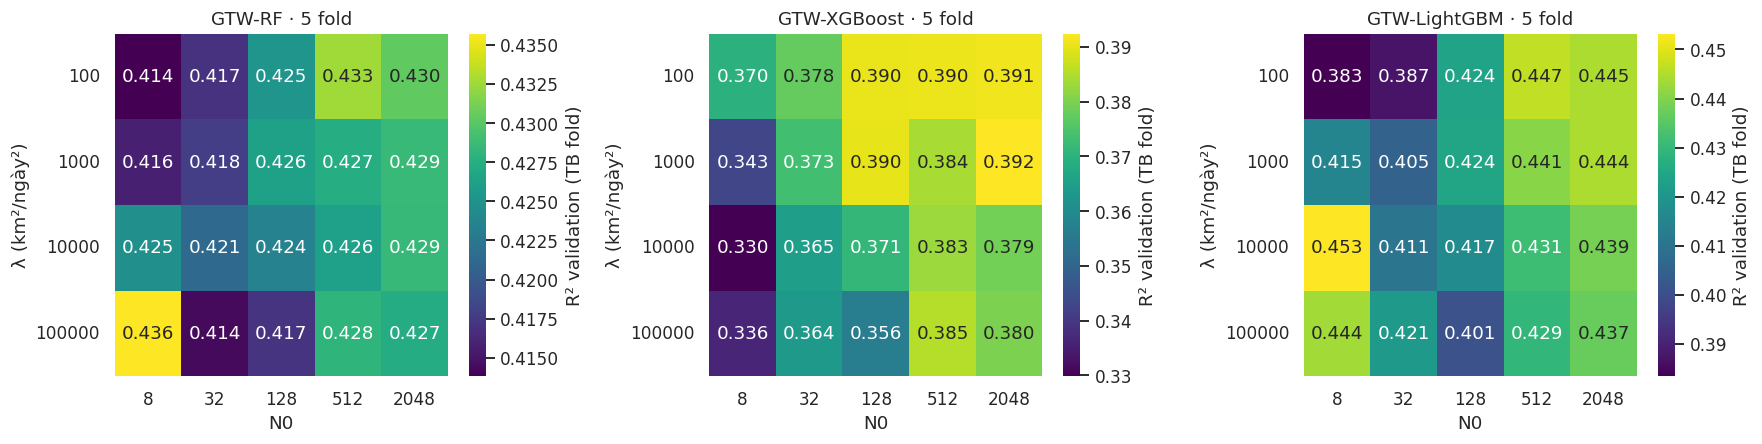

lambda    N0     R2  n_local_median
algo fold                                       
rf   0        100.0   512  0.292           473.0
     1     100000.0     8  0.306            28.0
     2     100000.0     8  0.634            30.0
     3        100.0   512  0.555           459.0
     4        100.0     8  0.526            79.0
xgb  0        100.0   512  0.274           473.0
     1        100.0   128  0.244           277.0
     2        100.0  2048  0.569           391.0
     3       1000.0  2048  0.558           459.0
     4        100.0     8  0.494            79.0
lgbm 0        100.0   512  0.307           473.0
     1     100000.0     8  0.319            28.0
     2       1000.0  2048  0.617           391.0
     3        100.0  2048  0.581           459.0
     4     100000.0     8  0.592            29.0

In [2]:
if grids:
    fig, axes = plt.subplots(1, len(grids), figsize=(5.4 * len(grids), 4.2), squeeze=False)
    for ax, (a, g) in zip(axes.ravel(), grids.items()):
        pv = g.pivot_table(index='lambda', columns='N0', values='R2', aggfunc='mean')
        sns.heatmap(pv, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar_kws={'label': 'R² validation (TB fold)'})
        ax.set_title(f'GTW-{R.ALGO[a]} · {g.fold.nunique()} fold'); ax.set_ylabel('λ (km²/ngày²)')
        ax.set_yticklabels([f'{float(t.get_text()):g}' for t in ax.get_yticklabels()], rotation=0)
    plt.tight_layout(); plt.show()
    chosen = pd.concat([g.loc[g.groupby('fold').R2.idxmax(), ['fold', 'lambda', 'N0', 'R2', 'n_local_median']].assign(algo=a)
                        for a, g in grids.items()])
    display(chosen.set_index(['algo', 'fold']).round(3))

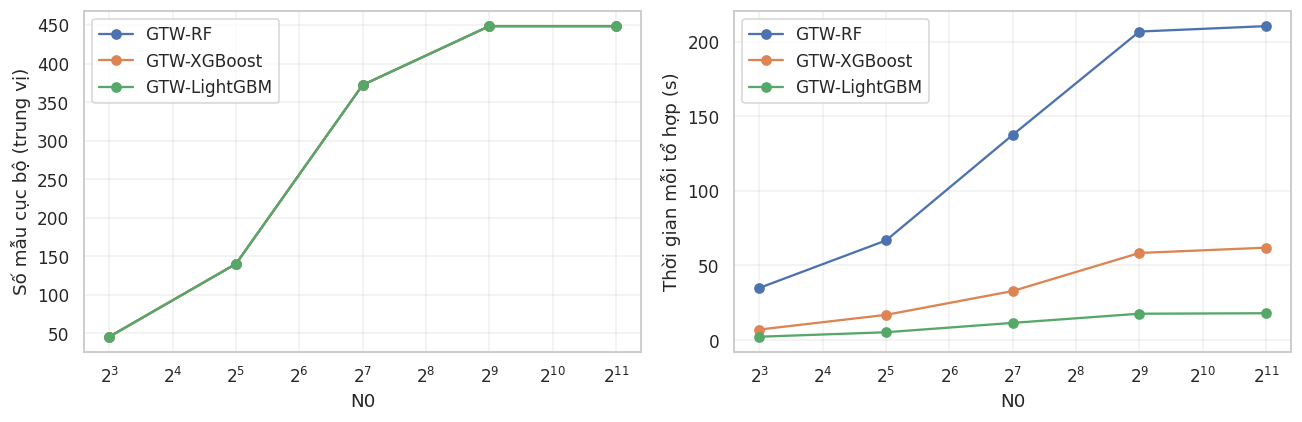

In [3]:
if grids:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for a, g in grids.items():
        m = g.groupby('N0')[['n_local_median', 'seconds']].mean()
        axes[0].plot(m.index, m.n_local_median, 'o-', label=f'GTW-{R.ALGO[a]}')
        axes[1].plot(m.index, m.seconds, 'o-', label=f'GTW-{R.ALGO[a]}')
    for ax, yl in zip(axes, ('Số mẫu cục bộ (trung vị)', 'Thời gian mỗi tổ hợp (s)')):
        ax.set_xscale('log', base=2); ax.set_xlabel('N0'); ax.set_ylabel(yl); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 2. Số mẫu của mô hình cục bộ (~ Fig. 4c)

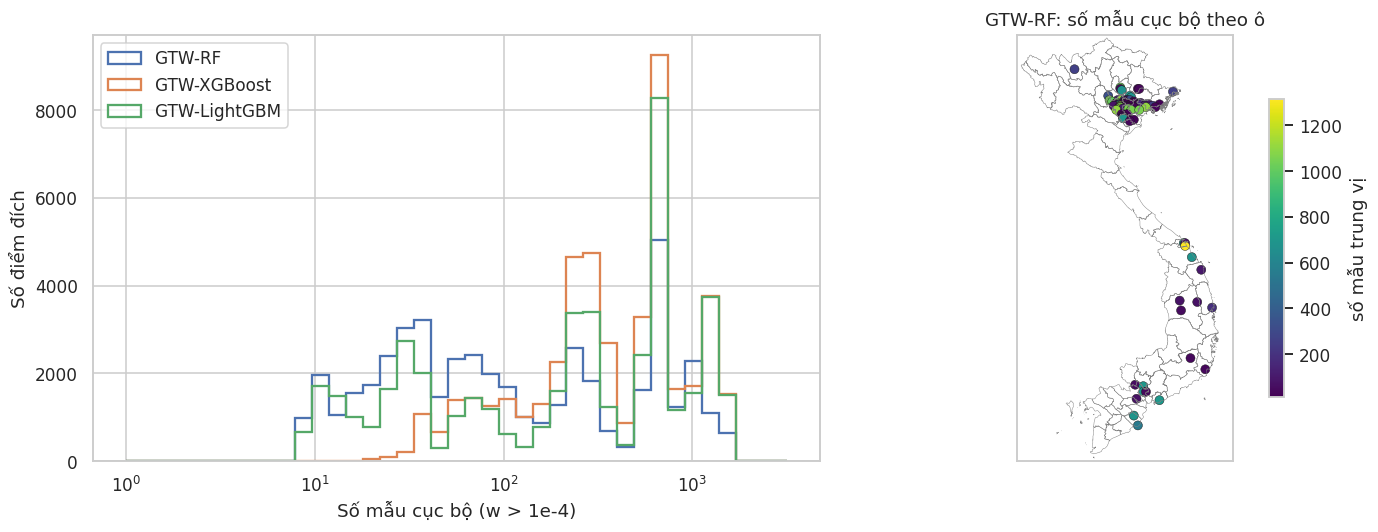

In [4]:
if preds:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for n, p in preds.items():
        axes[0].hist(p.n_local, bins=np.logspace(0, 3.5, 40), histtype='step', lw=1.5, label=n)
    axes[0].set_xscale('log'); axes[0].set_xlabel('Số mẫu cục bộ (w > 1e-4)'); axes[0].set_ylabel('Số điểm đích'); axes[0].legend()
    n0 = next(iter(preds))
    med = preds[n0].groupby('cell_id').n_local.median().rename('n_local').to_frame().join(cells.set_index('cell_id'))
    R.vn_axes(axes[1]); sc = axes[1].scatter(med.lon, med.lat, c=med.n_local, cmap='viridis', s=35, edgecolor='k', lw=0.3)
    plt.colorbar(sc, ax=axes[1], shrink=0.7, label='số mẫu trung vị'); axes[1].set_title(f'{n0}: số mẫu cục bộ theo ô')
    plt.tight_layout(); plt.show()

## 3. Độ quan trọng biến của các mô hình cục bộ (~ Fig. 3)

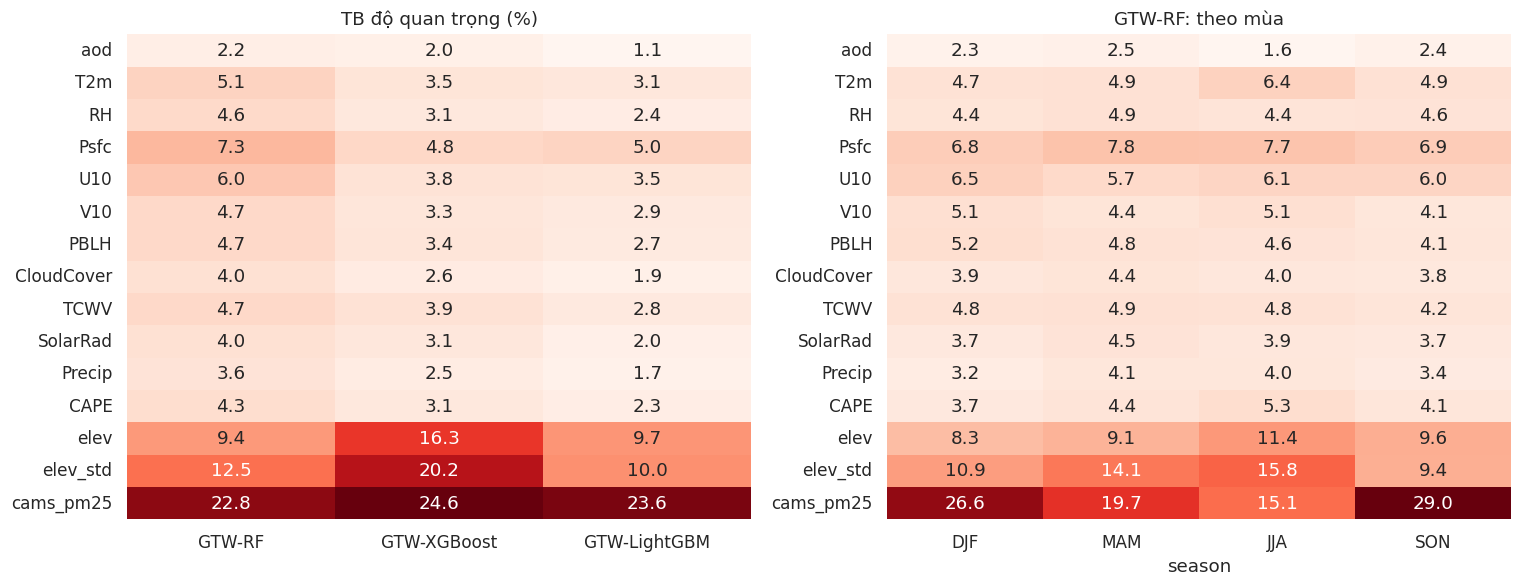

GTW-RF: thứ hạng TB của AOD = 12.3/15 · biến đứng đầu thường gặp: {'cams_pm25': 41.0, 'elev_std': 15.0, 'elev': 9.0}
GTW-XGBoost: thứ hạng TB của AOD = 11.4/15 · biến đứng đầu thường gặp: {'cams_pm25': 44.0, 'elev_std': 25.0, 'elev': 16.0}
GTW-LightGBM: thứ hạng TB của AOD = 11.5/15 · biến đứng đầu thường gặp: {'cams_pm25': 45.0, 'aod': 26.0, 'elev_std': 12.0}


In [5]:
imp_cols = [f'imp_{v}' for v in D.X_VARS]
if preds:
    T = pd.DataFrame({n: p[imp_cols].mean().rename(lambda c: c[4:]) * 100 for n, p in preds.items()})
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(T, annot=True, fmt='.1f', cmap='Reds', ax=axes[0], cbar=False); axes[0].set_title('TB độ quan trọng (%)')
    n = next(iter(preds)); P = preds[n].merge(frame[['cell_id', 'day', 'season']], on=['cell_id', 'day'])
    S = P.groupby('season')[imp_cols].mean().reindex(['DJF', 'MAM', 'JJA', 'SON']).T.rename(lambda c: c[4:]) * 100
    sns.heatmap(S, annot=True, fmt='.1f', cmap='Reds', ax=axes[1], cbar=False); axes[1].set_title(f'{n}: theo mùa')
    plt.tight_layout(); plt.show()
    for n, p in preds.items():
        rank = p[imp_cols].rank(axis=1, ascending=False)['imp_aod']
        top = pd.Series(np.array(D.X_VARS)[np.nanargmax(p[imp_cols].fillna(-1).to_numpy(), axis=1)]).value_counts(normalize=True).head(3)
        print(f'{n}: thứ hạng TB của AOD = {rank.mean():.1f}/{len(D.X_VARS)} · biến đứng đầu thường gặp: {(top * 100).round(0).to_dict()}')

## 4. GTW ↔ Global (LightGBM Optuna, cùng 15 biến x)

In [6]:
allp = {**R.load_global(), **preds}
names = [n for n in ('Global', *preds) if n in allp]
if len(names) > 1:
    J = R.joined(allp, frame, names)
    display(R.metrics_table(J, names).round(3))

,N,R2,R2_paper,RMSE,MAE,RPE,slope,bias,R2_fold_mean,R2_fold_sd
model,,,,,,,,,,
Global,46374,0.488,0.492,16.315,11.013,62.748,0.537,-0.191,0.466,0.105
GTW-RF,46374,0.528,0.546,15.658,10.272,60.219,0.643,0.287,0.513,0.130
GTW-XGBoost,46374,0.473,0.506,16.551,10.835,63.653,0.635,0.148,0.459,0.118
GTW-LightGBM,46374,0.524,0.537,15.729,10.497,60.495,0.623,0.076,0.512,0.123


## 5. Nhận xét (cập nhật 27/10/2026)

**Chỉ số gộp 5 fold, so với Global (LightGBM Optuna, cùng 15 biến x):**

| Mô hình | R² | RMSE | So với Global |
|---|---|---|---|
| Global | 0,488 | 16,32 | — |
| GTW-RF | 0,528 | 15,66 | RMSE −4,0% |
| GTW-LightGBM | 0,524 | 15,73 | RMSE −3,6% |
| GTW-XGBoost | 0,473 | 16,55 | RMSE +1,4% |

- **GTW-RF và GTW-LightGBM tốt hơn Global dù dùng cây mặc định** (Global thì được dò tham số). Mức cải thiện ~4% RMSE vẫn nhỏ hơn nhiều so với mức ~30% của paper.
- **GTW-XGBoost kém hơn Global một chút.**
- **GTW kéo giá trị cao xuống ít hơn:** độ dốc 0,62–0,64, so với 0,54 của Global. Đúng điều paper nêu: mô hình cục bộ bắt giá trị cao tốt hơn.
- **(λ, N0) được chọn nhảy giữa hai cực tùy fold.**
  - Kernel hẹp: N0 = 8 với λ = 10⁵, tức chỉ dùng ô gần và cùng ngày (~30 mẫu).
  - Kernel rộng: N0 = 512–2048 với λ = 100–1000, tức gần như mọi mẫu trong 30 ngày.
  - Không có cấu hình chung ổn định.
- **Độ quan trọng biến cục bộ**
  - CAMS PM2.5 đứng đầu ở 41–45% số mô hình cục bộ.
  - elev/elev_std đứng đầu ở 12–25%: trong một cửa sổ, DEM giúp phân biệt các ô train.
  - AOD trung bình hạng 11–12/15.
- **Điểm yếu:** ô Lào Cai (NW) có RMSE ~25, vì không có ô train nào gần. Đúng nhận định của paper về vùng trạm thưa.
- **So với Global -st** (R² 0,570): cả ba GTW đều kém hơn. Thêm biến không gian/thời gian vào mô hình global hiệu quả hơn, và rẻ hơn nhiều so với dựng một mô hình riêng cho từng điểm đích.